Considerăm o reţea de Markov de dimensiune mică care descrie distribuţia probabilităţilor pentru 5 variabile discrete
binare (cu valorile 0 şi 1): A1, A2, A3, A4 şi A5. Relaţiile de independenţă condiţionată dintre aceste variabile sunt descrise
de următoarele conexiuni: A1 este conectat cu A2 şi A3, A2 este conectat cu A4 şi A5, A3 este conectat cu A4, iar A4 este
conectat cu A5.
Se cunoaşte următoarea distribuţie a energiei pentru clicile maximale ale modelului:

$$\phi_C(a_C)=e^{\beta \cdot \sum _{i,j \in C, i<j}a_i a_j}$$

a) Vizualizaţi în pyAgrum graful reţelei Markov, iar apoi determinaţi clicile modelului.
b) Determinaţi probabilitatea comună a celor 5 variabile şi deduceţi stările de probabilitate maximă pentru acestea.
c) Explicaţi cum aţi modifica funcţiile de potenţial pentru a modela modelul Ising, în care sunt favorizate perechile
de vecini care au aceeaşi valoare.

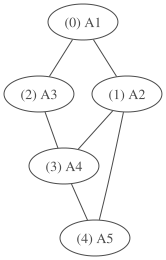

Clici: (A2, A4, A4), (A1, A2), (A1, A3), (A3, A4), (A2, A4)


In [ ]:
import pyagrum as gum
import pyagrum.lib.notebook as pln


g = gum.fastUndiGraph("A1-A2;A1-A3;A3-A4;A2-A4;A4-A5;A2-A5")
pln.show(g)

jtg = gum.JunctionTreeGenerator()
cg = jtg.junctionTree(g)

print("Clici: (A2, A4, A5), (A1, A2), (A1, A3), (A3, A4), (A2, A4)")

In [ ]:
import math
clici = [[0,1], [0,2], [2,3], [1,3,4]]
def phi(c, msk, beta):
    s = 0
    for i in c:
        for j in c:
            if i<j:
                s += ((msk>>i)&1)*((msk>>j)&1)
    return math.exp(s*beta)

def prob_comuna(beta):
    Z = 0
    for msk in range(32):
        prod = 1
        for c in clici:
            prod *= phi(c, msk, beta)
        Z += prod
    p = []
    for msk in range(32):
        prod = 1
        for c in clici:
            prod *= phi(c, msk, beta)
        p.append(prod/Z)
    return p

p = prob_comuna(1)
psorted = [(p[i], i) for i in range(32)]

print(psorted)

[(0.06978506562157012, 0), (0.06978506562157012, 1), (0.06978506562157012, 2), (0.025672490942975648, 3), (0.06978506562157012, 4), (0.025672490942975648, 5), (0.06978506562157012, 6), (0.009444381621580797, 7), (0.06978506562157012, 8), (0.06978506562157012, 9), (0.025672490942975648, 10), (0.009444381621580797, 11), (0.025672490942975648, 12), (0.009444381621580797, 13), (0.009444381621580797, 14), (0.0012781580617512967, 15), (0.06978506562157012, 16), (0.06978506562157012, 17), (0.025672490942975648, 18), (0.009444381621580797, 19), (0.06978506562157012, 20), (0.025672490942975648, 21), (0.025672490942975648, 22), (0.003474393833156984, 23), (0.025672490942975648, 24), (0.025672490942975648, 25), (0.0034743938331569836, 26), (0.0012781580617512965, 27), (0.009444381621580797, 28), (0.003474393833156984, 29), (0.0012781580617512965, 30), (0.00017297988330827163, 31)]
